<a href="https://colab.research.google.com/github/Sambhav-Budhiraja/breast-cancer-xai/blob/main/LUSIP_2026.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Importing all the libraries which we use seen from the papers

In [ ]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

from PIL import Image

import torch
import torch.nn as nn

from torchvision import datasets
from torchvision import transforms
from torchvision import models
from torch.utils.data import DataLoader

Downloading Dataset

In [ ]:
import kagglehub

path = kagglehub.dataset_download("sabahesaraki/breast-ultrasound-images-dataset")

print("Path to dataset files:", path)

100%|██████████| 195M/195M [00:01<00:00, 112MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/sabahesaraki/breast-ultrasound-images-dataset/versions/1


Seeing the dataset

In [ ]:
import os
path="/kaggle/input/breast-ultrasound-images-dataset"
print(path)
print("\nFolders inside dataset:")
print(os.listdir(path))

/kaggle/input/breast-ultrasound-images-dataset

Folders inside dataset:
['Dataset_BUSI_with_GT']


In [ ]:
dataset_path = os.path.join(path, os.listdir(path)[0])
print(dataset_path)
print(os.listdir(dataset_path))
for folder in os.listdir(dataset_path):

    folder_path = os.path.join(dataset_path, folder)

    if os.path.isdir(folder_path):

        images = [
            img
            for img in os.listdir(folder_path)
            if "_mask" not in img
        ]

        print(f"{folder}: {len(images)} images")

/kaggle/input/breast-ultrasound-images-dataset/Dataset_BUSI_with_GT
['benign', 'normal', 'malignant']
benign: 437 images
normal: 133 images
malignant: 210 images


Labeling each folder as number

In [ ]:

class_names = ["benign", "malignant", "normal"]

label_map = {
    "benign": 0,
    "malignant": 1,
    "normal": 2
}

image_paths = []
labels = []

Reading images ignoring mask

In [ ]:
for class_name in class_names:

    class_folder = os.path.join(dataset_path, class_name)

    for image_name in os.listdir(class_folder):

        if "_mask" in image_name:
            continue

        image_path = os.path.join(class_folder, image_name)

        image_paths.append(image_path)
        labels.append(label_map[class_name])

print("Total Images :", len(image_paths))
print("Total Labels :", len(labels))

Total Images : 780
Total Labels : 780


In [ ]:
from sklearn.utils.class_weight import compute_class_weight
import numpy as np
import torch
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)
class_weights = compute_class_weight(
    class_weight="balanced",
    classes=np.unique(labels),
    y=labels
)

class_weights = torch.tensor(class_weights, dtype=torch.float).to(device)

print(class_weights)

cuda
tensor([0.5950, 1.2381, 1.9549], device='cuda:0')


First Image : /kaggle/input/breast-ultrasound-images-dataset/Dataset_BUSI_with_GT/benign/benign (2).png
First Label : 0


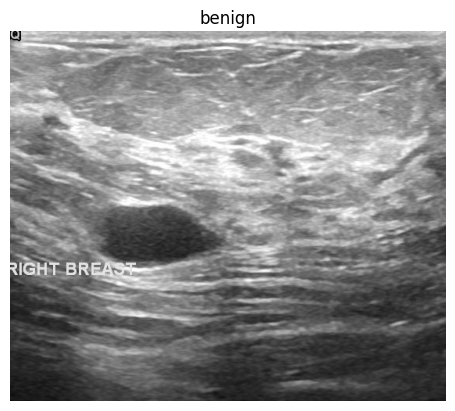

In [ ]:

import matplotlib.pyplot as plt
from PIL import Image
print("First Image :", image_paths[0])
print("First Label :", labels[0])

img = Image.open(image_paths[0])

plt.imshow(img, cmap="gray")
plt.title(class_names[labels[0]])
plt.axis("off")
plt.show()

Class Distribution

Counter({0: 437, 1: 210, 2: 133})


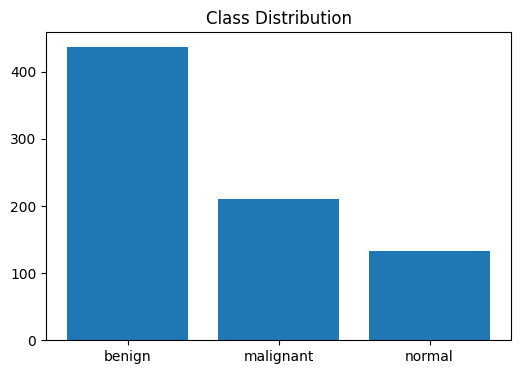

In [ ]:
from collections import Counter

counter = Counter(labels)

print(counter)

plt.figure(figsize=(6,4))
plt.bar(class_names, counter.values())
plt.title("Class Distribution")
plt.show()

Preprocessing according to the paper

Training transform

In [ ]:
from torchvision import transforms
train_transform = transforms.Compose([

    transforms.Resize((224,224)),

    transforms.RandomHorizontalFlip(),

    transforms.RandomRotation(15),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485,0.456,0.406],
        std=[0.229,0.224,0.225]
    )

])

Validation and test transform

In [ ]:
test_transform = transforms.Compose([

    transforms.Resize((224,224)),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485,0.456,0.406],
        std=[0.229,0.224,0.225]
    )

])

Creating Custom Datasetss

In [ ]:
from torch.utils.data import Dataset

class BreastCancerDataset(Dataset):

    def __init__(self, image_paths, labels, transform=None):

        self.image_paths = image_paths
        self.labels = labels
        self.transform = transform

    def __len__(self):

        return len(self.image_paths)

    def __getitem__(self, idx):

        image = Image.open(self.image_paths[idx]).convert("RGB")

        label = self.labels[idx]

        if self.transform:
            image = self.transform(image)

        return image, label

In [ ]:
full_dataset = BreastCancerDataset(
    image_paths,
    labels

)

print("Dataset Size :", len(full_dataset))

Dataset Size : 780


Same Spilt as paper

In [ ]:
from torch.utils.data import random_split

dataset_size = len(full_dataset)

train_size = int(0.70 * dataset_size)

val_size = int(0.15 * dataset_size)

test_size = dataset_size - train_size - val_size

train_dataset, val_dataset, test_dataset = random_split(

    full_dataset,

    [train_size, val_size, test_size],

    generator=torch.Generator().manual_seed(42)

)

In [ ]:
train_indices = train_dataset.indices
val_indices = val_dataset.indices
test_indices = test_dataset.indices

train_dataset = BreastCancerDataset(
    [image_paths[i] for i in train_indices],
    [labels[i] for i in train_indices],
    transform=train_transform
)

val_dataset = BreastCancerDataset(
    [image_paths[i] for i in val_indices],
    [labels[i] for i in val_indices],
    transform=test_transform
)

test_dataset = BreastCancerDataset(
    [image_paths[i] for i in test_indices],
    [labels[i] for i in test_indices],
    transform=test_transform
)

In [ ]:
train_loader = DataLoader(

    train_dataset,

    batch_size=32,

    shuffle=True,

    num_workers=2

)

val_loader = DataLoader(

    val_dataset,

    batch_size=32,

    shuffle=False,

    num_workers=2

)

test_loader = DataLoader(

    test_dataset,

    batch_size=32,

    shuffle=False,

    num_workers=2

)

In [ ]:
images, labels = next(iter(train_loader))

print("Images Shape :", images.shape)

print("Labels Shape :", labels.shape)

Images Shape : torch.Size([32, 3, 224, 224])
Labels Shape : torch.Size([32])


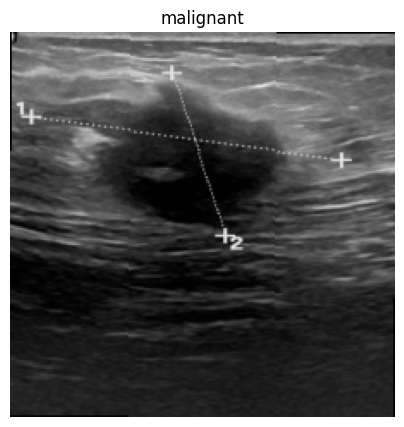

In [ ]:
image = images[0].permute(1,2,0).numpy()

mean = np.array([0.485,0.456,0.406])
std = np.array([0.229,0.224,0.225])

image = image * std + mean
image = np.clip(image,0,1)

plt.figure(figsize=(5,5))
plt.imshow(image)
plt.title(class_names[labels[0]])
plt.axis("off")
plt.show()

Implementing Model_ResNet50

In [ ]:
from torchvision.models import resnet50, ResNet50_Weights
import torch.nn as nn

Loading the weights of pre trained model

In [ ]:
weights = ResNet50_Weights.DEFAULT

model = resnet50(weights=weights)
print(model)

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 168MB/s]


ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): Bottleneck(
      (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (downsample): Sequential(
        (0): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 

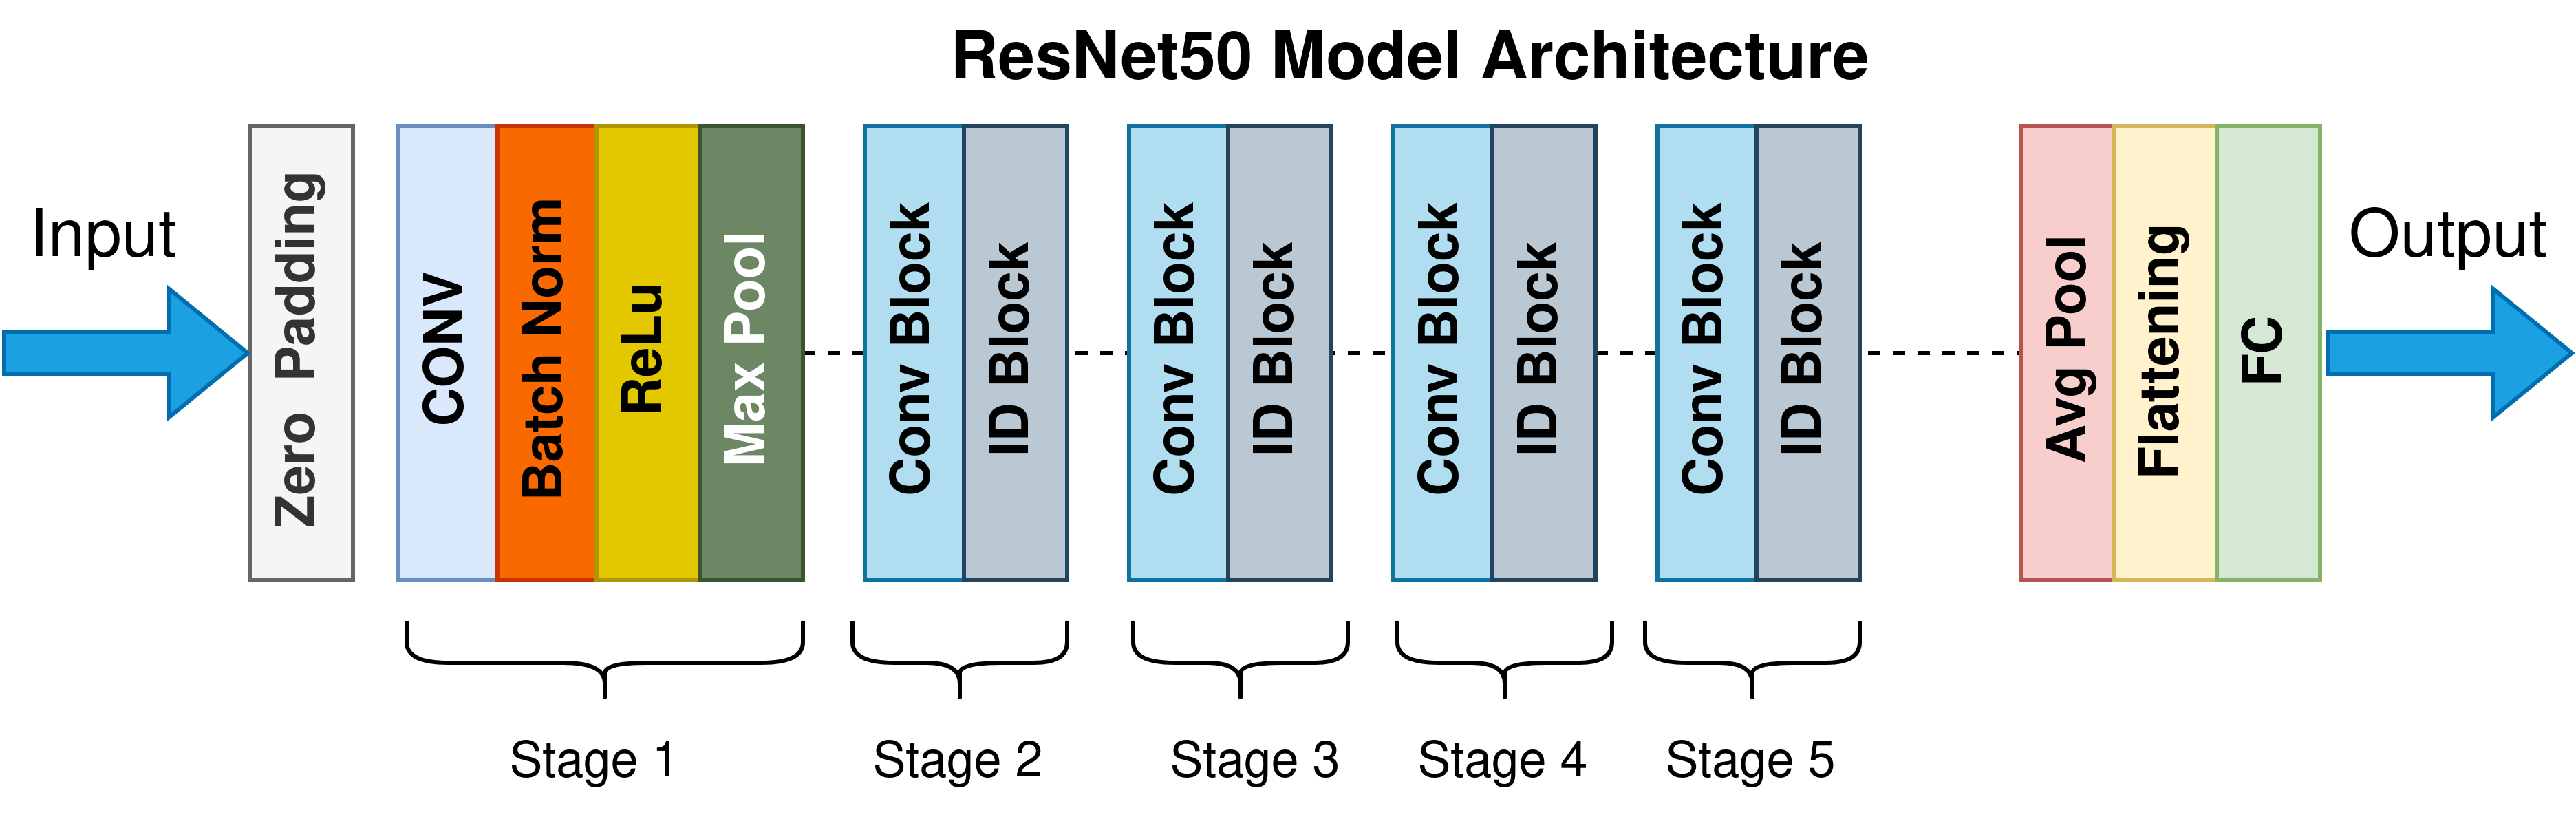

Since we need changes in FC i.e. fully connected layer we are seeing it

In [ ]:
print(model.fc)

Linear(in_features=2048, out_features=1000, bias=True)


Since we need only 3 classes bcz of our dataset therefore changing the in fc. i.e. passing 2048 features from each image to 1024 neurons and further classifying in 3 classes. I have added fropout which is not mentioned in paper since our dataset is small reduces overfitting

In [ ]:
model.fc = nn.Sequential(

    nn.Linear(2048, 1024),

    nn.ReLU(),

    nn.Dropout(0.5),

    nn.Linear(1024, 3)

)

print(model.fc)

Sequential(
  (0): Linear(in_features=2048, out_features=1024, bias=True)
  (1): ReLU()
  (2): Dropout(p=0.5, inplace=False)
  (3): Linear(in_features=1024, out_features=3, bias=True)
)


We are using Transfer learning by using requires_grad if this is false then weights for that neurons will not be computed therefore no backpropogation there no weights will be updated then we are freexing some layers

In [ ]:
for param in model.parameters():
    param.requires_grad = False

for param in model.fc.parameters():
    param.requires_grad = True

In [ ]:
trainable = 0
total = 0

for param in model.parameters():
    total += param.numel()
    if param.requires_grad:
        trainable += param.numel()

print(f"Total Parameters: {total:,}")
print(f"Trainable Parameters: {trainable:,}")
print(f"Frozen Parameters: {total-trainable:,}")

Total Parameters: 25,609,283
Trainable Parameters: 2,101,251
Frozen Parameters: 23,508,032


Training

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = model.to(device)

import torch
import torch.nn as nn
criterion = nn.CrossEntropyLoss(weight=class_weights)

optimizer = torch.optim.Adam(
    model.fc.parameters(),
    lr=0.0001
)

We used cross entropy loss bcz this is useful in calculating loss for different probabilities.

In [ ]:
num_epochs = 10
best_val_accuracy = 0.0

In [ ]:
from tqdm import tqdm

train_losses = []
train_accuracies = []

for epoch in range(num_epochs):

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in tqdm(train_loader):

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        running_loss += loss.item()

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)

        correct += (predicted == labels).sum().item()

    train_loss = running_loss / len(train_loader)

    train_accuracy = 100 * correct / total

    train_losses.append(train_loss)
    train_accuracies.append(train_accuracy)

    print(f"Epoch [{epoch+1}/{num_epochs}] | Loss: {train_loss:.4f} | Accuracy: {train_accuracy:.2f}%")

torch.save(model.state_dict(), "resnet50_final.pth")

print("Model saved as resnet50_final.pth")

100%|██████████| 18/18 [00:07<00:00,  2.28it/s]


Epoch [1/10] | Loss: 1.0860 | Accuracy: 48.35%


100%|██████████| 18/18 [00:05<00:00,  3.43it/s]


Epoch [2/10] | Loss: 1.0638 | Accuracy: 41.21%


100%|██████████| 18/18 [00:05<00:00,  3.08it/s]


Epoch [3/10] | Loss: 1.0203 | Accuracy: 63.74%


... (10 outputs left out)

100%|██████████| 18/18 [00:05<00:00,  3.38it/s]


Epoch [9/10] | Loss: 0.8423 | Accuracy: 71.06%


100%|██████████| 18/18 [00:06<00:00,  2.76it/s]

Epoch [10/10] | Loss: 0.8141 | Accuracy: 67.77%
Model saved as resnet50_final.pth


In [ ]:
train_accuracy = 100 * correct / total
print(
    f"Epoch [{epoch+1}/{num_epochs}] | "
    f"Train Loss: {train_loss:.4f} | "
    f"Train Accuracy: {train_accuracy:.2f}%"
)


Epoch [10/10] | Train Loss: 0.8141 | Train Accuracy: 67.77%


In [ ]:
learning_rates = [1e-5, 1e-4, 1e-3]

results = []

for lr in learning_rates:

    print("="*60)
    print(f"Training with Learning Rate = {lr}")
    print("="*60)

    model = resnet50(weights=ResNet50_Weights.DEFAULT)

    model.fc = nn.Sequential(
        nn.Linear(2048,1024),
        nn.ReLU(),
        nn.Dropout(0.5),
        nn.Linear(1024,3)
    )
    model = model.to(device)

    for param in model.parameters():
        param.requires_grad = False

    for param in model.fc.parameters():
        param.requires_grad = True


    criterion = nn.CrossEntropyLoss(weight=class_weights)

    optimizer = torch.optim.Adam(
        model.fc.parameters(),
        lr=lr
    )


    from tqdm import tqdm

    for epoch in range(num_epochs):

        model.train()

        running_loss = 0.0
        correct = 0
        total = 0

        for images, labels in tqdm(train_loader):

            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = model(images)

            loss = criterion(outputs, labels)

            loss.backward()

            optimizer.step()

            running_loss += loss.item()

            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)

            correct += (predicted == labels).sum().item()

        train_loss = running_loss / len(train_loader)

        train_accuracy = 100 * correct / total


    results.append({
        "Learning Rate": lr,
        "Train Accuracy": train_accuracy,
        "Train Loss": train_loss
    })

Training with Learning Rate = 1e-05


100%|██████████| 18/18 [00:05<00:00,  3.08it/s]


Training with Learning Rate = 0.0001


100%|██████████| 18/18 [00:05<00:00,  3.23it/s]


Training with Learning Rate = 0.001


100%|██████████| 18/18 [00:06<00:00,  2.88it/s]


In [ ]:
batch_sizes = [16,32,64]

results_batch = []

for batch_size in batch_sizes:

    print(f"\nBatch Size = {batch_size}")

    train_loader = DataLoader(
        train_dataset,
        batch_size=batch_size,
        shuffle=True
    )

    val_loader = DataLoader(
        val_dataset,
        batch_size=batch_size,
        shuffle=False
    )
    model = model.to(device)
    from tqdm import tqdm

    for epoch in range(num_epochs):

        model.train()

        running_loss = 0.0
        correct = 0
        total = 0

        for images, labels in tqdm(train_loader):

            images = images.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = model(images)

            loss = criterion(outputs, labels)

            loss.backward()

            optimizer.step()

            running_loss += loss.item()

            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)

            correct += (predicted == labels).sum().item()

        train_loss = running_loss / len(train_loader)

        train_accuracy = 100 * correct / total

    results_batch.append({
        "Batch Size": batch_size,
        "Train Accuracy": train_accuracy,
        "Train Loss": train_loss
    })


Batch Size = 16


100%|██████████| 35/35 [00:08<00:00,  3.96it/s]



Batch Size = 32


100%|██████████| 18/18 [00:08<00:00,  2.20it/s]



Batch Size = 64


100%|██████████| 9/9 [00:08<00:00,  1.10it/s]


In [ ]:
epoch_values = [5,10,15]

results_epochs = []

model = model.to(device)
for num_epochs in epoch_values:

    print(f"\nTraining for {num_epochs} epochs")

    from tqdm import tqdm

    for epoch in range(num_epochs):

        model.train()

        running_loss = 0.0
        correct = 0
        total = 0

        for images, labels in tqdm(train_loader):
            images = images.to(device)
            labels = labels.to(device)
            optimizer.zero_grad()

            outputs = model(images)

            loss = criterion(outputs, labels)

            loss.backward()

            optimizer.step()

            running_loss += loss.item()

            _, predicted = torch.max(outputs, 1)

            total += labels.size(0)

            correct += (predicted == labels).sum().item()

        train_loss = running_loss / len(train_loader)

        train_accuracy = 100 * correct / total

    results_epochs.append({
        "Epochs": num_epochs,
        "Train Accuracy": train_accuracy,
        "Train Loss": train_loss
    })


Training for 5 epochs


100%|██████████| 9/9 [00:08<00:00,  1.06it/s]



Training for 10 epochs


100%|██████████| 9/9 [00:07<00:00,  1.18it/s]



Training for 15 epochs


100%|██████████| 9/9 [00:08<00:00,  1.09it/s]


In [ ]:
import pandas as pd

lr_results = pd.DataFrame(results)
batch_results = pd.DataFrame(results_batch)
epoch_results = pd.DataFrame(results_epochs)

print(lr_results)
print(batch_results)
print(epoch_results)

   Learning Rate  Train Accuracy  Train Loss
0        0.00001       61.904762    1.056781
1        0.00010       71.978022    0.817315
2        0.00100       63.186813    0.844076
   Batch Size  Train Accuracy  Train Loss
0          16       69.963370    0.669741
1          32       74.542125    0.625495
2          64       77.838828    0.495037
   Epochs  Train Accuracy  Train Loss
0       5       80.769231    0.461028
1      10       82.417582    0.422774
2      15       81.318681    0.408931


In [ ]:
best_lr = 0.001
best_batch_size = 64
best_num_epochs = 15

best model training

In [ ]:
from torchvision.models import resnet50, ResNet50_Weights
import torch.nn as nn
import torch

model = resnet50(weights=ResNet50_Weights.DEFAULT)

model.fc = nn.Sequential(
    nn.Linear(2048, 1024),
    nn.ReLU(),
    nn.Dropout(0.5),
    nn.Linear(1024, 3)
)

for param in model.parameters():
    param.requires_grad = False

for param in model.fc.parameters():
    param.requires_grad = True

model = model.to(device)

criterion = nn.CrossEntropyLoss(weight=class_weights)

optimizer = torch.optim.Adam(
    model.fc.parameters(),
    lr=best_lr
)

train_losses = []
train_accuracies = []

In [ ]:
from tqdm import tqdm

for epoch in range(best_num_epochs):

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in tqdm(train_loader):

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        running_loss += loss.item()

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    train_loss = running_loss / len(train_loader)
    train_accuracy = 100 * correct / total

    train_losses.append(train_loss)
    train_accuracies.append(train_accuracy)

    print(
        f"Epoch [{epoch+1}/{best_num_epochs}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Train Accuracy: {train_accuracy:.2f}%"
    )

100%|██████████| 9/9 [00:08<00:00,  1.09it/s]


Epoch [1/15] | Train Loss: 1.0686 | Train Accuracy: 38.10%


100%|██████████| 9/9 [00:07<00:00,  1.17it/s]


Epoch [2/15] | Train Loss: 0.9896 | Train Accuracy: 53.11%


100%|██████████| 9/9 [00:08<00:00,  1.08it/s]


Epoch [3/15] | Train Loss: 0.8652 | Train Accuracy: 60.26%


... (20 outputs left out)

100%|██████████| 9/9 [00:08<00:00,  1.09it/s]


Epoch [14/15] | Train Loss: 0.6193 | Train Accuracy: 72.71%


100%|██████████| 9/9 [00:08<00:00,  1.07it/s]

Epoch [15/15] | Train Loss: 0.5536 | Train Accuracy: 76.19%


In [ ]:
torch.save(model.state_dict(), "resnet50_final.pth")

print("Model saved successfully as resnet50_final.pth")

Model saved successfully as resnet50_final.pth


In [ ]:
model.eval()

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): Bottleneck(
      (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (downsample): Sequential(
        (0): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 

In [ ]:
val_running_loss = 0.0
val_correct = 0
val_total = 0

val_losses = []
val_accuracies = []

with torch.no_grad():

    for images, labels in val_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)

        loss = criterion(outputs, labels)

        val_running_loss += loss.item()

        _, predicted = torch.max(outputs, 1)

        val_total += labels.size(0)
        val_correct += (predicted == labels).sum().item()

val_loss = val_running_loss / len(val_loader)
val_accuracy = 100 * val_correct / val_total

val_losses.append(val_loss)
val_accuracies.append(val_accuracy)

print(f"Validation Loss: {val_loss:.4f}")
print(f"Validation Accuracy: {val_accuracy:.2f}%")


Validation Loss: 0.7800
Validation Accuracy: 64.96%


In [ ]:
import os

print(os.path.exists("resnet50_final.pth"))

True


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

In [ ]:
model.eval()

test_running_loss = 0.0
test_correct = 0
test_total = 0

all_labels = []
all_predictions = []
all_probabilities = []
with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        probabilities = torch.softmax(outputs, dim=1)
        loss = criterion(outputs, labels)

        test_running_loss += loss.item()

        _, predicted = torch.max(outputs, 1)

        test_total += labels.size(0)
        test_correct += (predicted == labels).sum().item()

        all_labels.extend(labels.cpu().numpy())
        all_predictions.extend(predicted.cpu().numpy())
        all_probabilities.extend(probabilities.cpu().numpy())

test_loss = test_running_loss / len(test_loader)
test_accuracy = 100 * test_correct / test_total

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.2f}%")

Test Loss: 0.7259
Test Accuracy: 73.50%


In [ ]:
precision = precision_score(
    all_labels,
    all_predictions,
    average="weighted"
)

recall = recall_score(
    all_labels,
    all_predictions,
    average="weighted"
)

f1 = f1_score(
    all_labels,
    all_predictions,
    average="weighted"
)

print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1 Score  : {f1:.4f}")

Precision : 0.7408
Recall    : 0.7350
F1 Score  : 0.7311


In [ ]:
print(classification_report(
    all_labels,
    all_predictions,
    target_names=["Benign", "Malignant", "Normal"]
))

              precision    recall  f1-score   support

      Benign       0.76      0.82      0.79        57
   Malignant       0.77      0.57      0.66        40
      Normal       0.64      0.80      0.71        20

    accuracy                           0.74       117
   macro avg       0.72      0.73      0.72       117
weighted avg       0.74      0.74      0.73       117



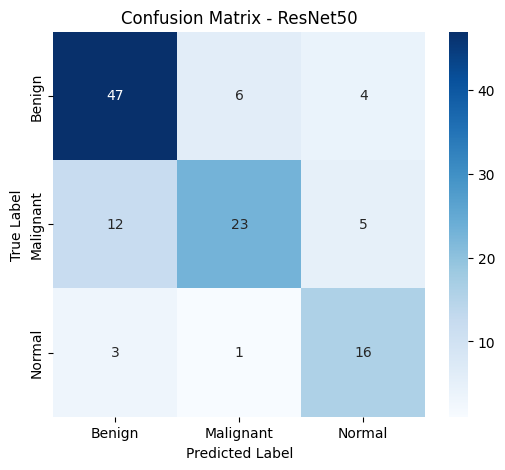

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(all_labels, all_predictions)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Benign", "Malignant", "Normal"],
    yticklabels=["Benign", "Malignant", "Normal"]
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix - ResNet50")

plt.show()

In [ ]:
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_auc_score

# Convert labels to one-hot format
true_labels = label_binarize(all_labels, classes=[0, 1, 2])

auc = roc_auc_score(
    true_labels,
    all_probabilities,
    multi_class="ovr"
)

print(f"ROC-AUC Score: {auc:.4f}")

ROC-AUC Score: 0.8790


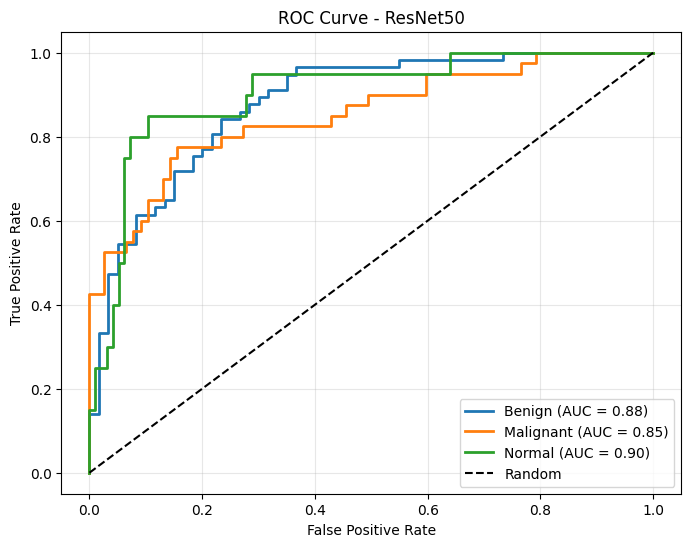

In [ ]:
from sklearn.metrics import roc_curve, auc

true_labels = label_binarize(all_labels, classes=[0,1,2])

class_names = ["Benign","Malignant","Normal"]

plt.figure(figsize=(8,6))

for i in range(3):

    fpr, tpr, _ = roc_curve(
        true_labels[:,i],
        [p[i] for p in all_probabilities]
    )

    roc_auc = auc(fpr, tpr)

    plt.plot(
        fpr,
        tpr,
        linewidth=2,
        label=f"{class_names[i]} (AUC = {roc_auc:.2f})"
    )

plt.plot([0,1],[0,1],'k--',label="Random")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - ResNet50")
plt.legend()

plt.grid(alpha=0.3)

plt.show()

In [ ]:
torch.save(model.state_dict(), "resnet50_weighted_final.pth")

implementing paper 4(grad-cam, shap, lime)

In [ ]:
!pip install grad-cam

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.8/7.8 MB 14.3 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for grad-cam: filename=grad_cam-1.5.5-py3-none-any.whl size=44285 sha256=ab16b588d3ba9df44f2be88c3e525850bf97d6fd0f1b4a91973f9c173a5b0a2e
  Stored in directory: /root/.cache/pip/wheels/fb/3b/09/2afc520f3d69bc26ae6bd87416759c820a3f7d05c1a077bbf6
Successfully built grad-cam


In [ ]:
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

gradcam uses last layer of conv layer[-1](4th layer in resnet) since it needs feature maps(rich)

In [ ]:
target_layers = [model.layer4[-1].conv3]

In [ ]:
cam = GradCAM(
    model=model,
    target_layers=target_layers
)

In [ ]:
for param in model.layer4.parameters():
    param.requires_grad = True

for name, param in model.named_parameters():
    if "layer4.0.conv1.weight" in name:
        print(name, param.requires_grad)

layer4.0.conv1.weight True


taking image first from testing data, since gradcam does one pred at a time, we did images[0] and unsqueeze to make size(1,...)

In [ ]:
images, labels = next(iter(test_loader))

input_tensor = images[0].unsqueeze(0).to(device)

true_label = labels[0].item()

print("True Label:", true_label)
print("Input Shape:", input_tensor.shape)

True Label: 0
Input Shape: torch.Size([1, 3, 224, 224])


In [ ]:
targets = None

grayscale_cam = cam(
    input_tensor=input_tensor,
    targets=targets
)

print(grayscale_cam.shape)

(1, 224, 224)


image back to rgb


In [ ]:
image = images[0].permute(1, 2, 0).cpu().numpy()

mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])

image = image * std + mean
image = np.clip(image, 0, 1)

In [ ]:
from pytorch_grad_cam.utils.image import show_cam_on_image

visualization = show_cam_on_image(
    image,
    grayscale_cam[0],
    use_rgb=True
)

  Blue → almost no contribution.
Green → moderate contribution.
 Yellow → high contribution.
 Red → strongest contribution to the prediction.

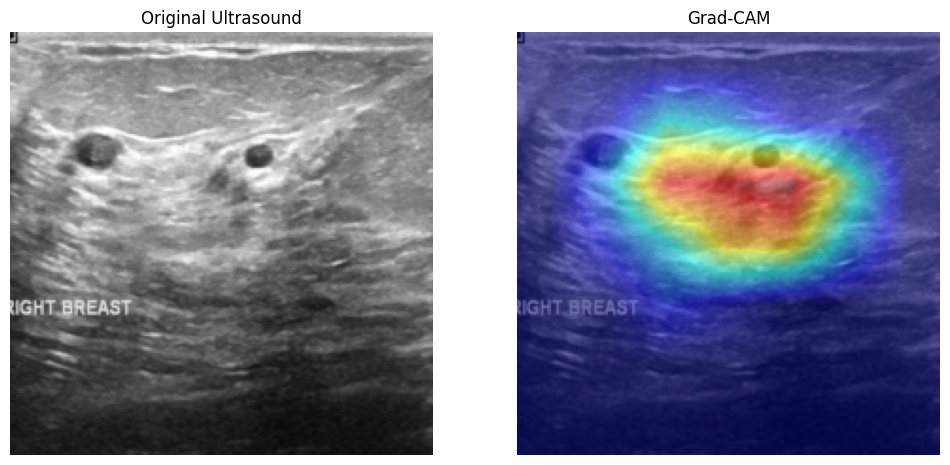

In [ ]:
plt.figure(figsize=(12,6))

plt.subplot(1,2,1)
plt.imshow(image)
plt.title("Original Ultrasound")
plt.axis("off")

plt.subplot(1,2,2)
plt.imshow(visualization)
plt.title("Grad-CAM")
plt.axis("off")

plt.show()

Now Shap and Lime will explain the GRADCAM results

In [ ]:
!pip install shap

In [ ]:
import shap
import torch

In [ ]:
model.eval()

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): Bottleneck(
      (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (downsample): Sequential(
        (0): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 

In [ ]:
images, labels = next(iter(test_loader))

input_tensor = images[0].unsqueeze(0).to(device)

print(input_tensor.shape)

torch.Size([1, 3, 224, 224])


selected 100 images, to save gpu power

In [ ]:
background, _ = next(iter(train_loader))

background = background[:100].to(device)

In [ ]:
explainer = shap.GradientExplainer(
    model,
    background
)

In [ ]:
shap_values = explainer.shap_values(input_tensor)

In [ ]:
print(type(shap_values))

if isinstance(shap_values, list):
    print("Number of classes:", len(shap_values))
    for i, value in enumerate(shap_values):
        print(f"Class {i}: {value.shape}")
else:
    print(shap_values.shape)

<class 'numpy.ndarray'>
(1, 3, 224, 224, 3)


In [ ]:
image = input_tensor.squeeze(0).permute(1, 2, 0).cpu().numpy()

mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])

image = image * std + mean
image = np.clip(image, 0, 1)

In [ ]:
model.eval()

with torch.no_grad():
    output = model(input_tensor)
    predicted_class = torch.argmax(output, dim=1).item()

print("Predicted Class:", predicted_class)

Predicted Class: 0


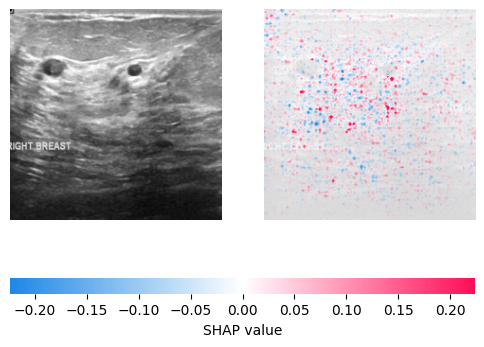

In [ ]:
pred_class = predicted_class

shap.image_plot(
    [shap_values[:, pred_class]],
    image[np.newaxis]
)

LIME

In [ ]:
!pip install lime

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 11.5 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for lime: filename=lime-0.2.0.1-py3-none-any.whl size=283834 sha256=8fcc706a3d9313da83e31cbccbaa2226cb9ad9be5fafcfcae242317c40fcec44
  Stored in directory: /root/.cache/pip/wheels/e7/5d/0e/4b4fff9a47468fed5633211fb3b76d1db43fe806a17fb7486a
Successfully built lime


In [ ]:
import lime
from lime import lime_image

from skimage.segmentation import mark_boundaries

import numpy as np
import matplotlib.pyplot as plt

In [ ]:
model.eval()

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): Bottleneck(
      (conv1): Conv2d(64, 64, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (conv3): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 1), bias=False)
      (bn3): BatchNorm2d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (downsample): Sequential(
        (0): Conv2d(64, 256, kernel_size=(1, 1), stride=(1, 

In [ ]:
def predict(images):

    images = torch.tensor(images, dtype=torch.float32)

    images = images.permute(0,3,1,2)

    images = images.to(device)

    with torch.no_grad():

        outputs = model(images)

        probs = torch.softmax(outputs, dim=1)

    return probs.cpu().numpy()

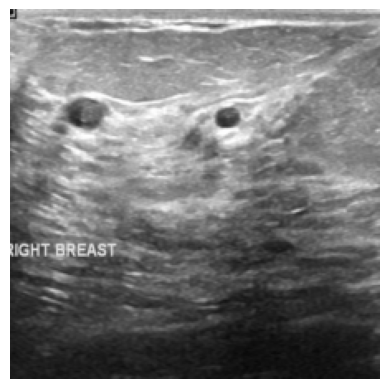

In [ ]:
images, labels = next(iter(test_loader))

input_image = images[0].permute(1,2,0).cpu().numpy()

mean = np.array([0.485,0.456,0.406])
std = np.array([0.229,0.224,0.225])

input_image = input_image * std + mean

input_image = np.clip(input_image,0,1)

plt.imshow(input_image)
plt.axis("off")
plt.show()

In [ ]:
explainer = lime_image.LimeImageExplainer()

In [ ]:
explanation = explainer.explain_instance(

    input_image,

    predict,

    top_labels=1,

    hide_color=0,

    num_samples=1000

)

  0%|          | 0/1000 [00:00<?, ?it/s]

In [ ]:
from skimage.segmentation import mark_boundaries

temp, mask = explanation.get_image_and_mask(

    explanation.top_labels[0],

    positive_only=True,

    num_features=5,

    hide_rest=False

)

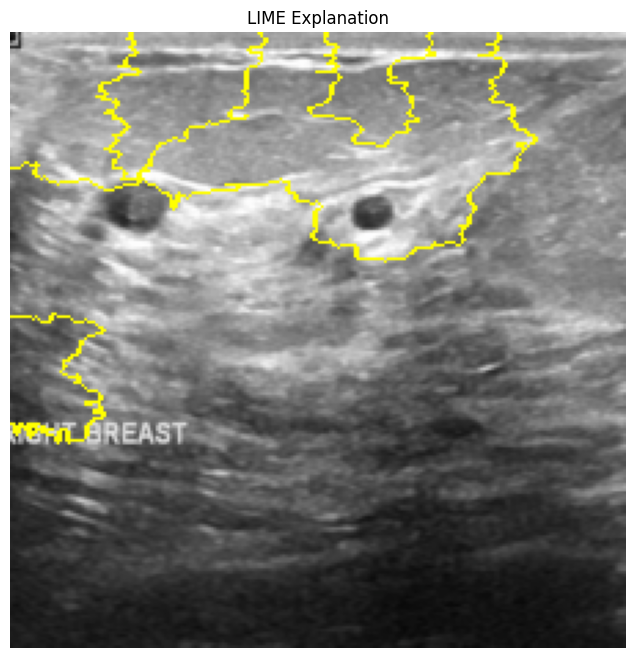

In [ ]:
plt.figure(figsize=(8,8))

plt.imshow(mark_boundaries(temp, mask))

plt.title("LIME Explanation")

plt.axis("off")

plt.show()

MobileNetV2
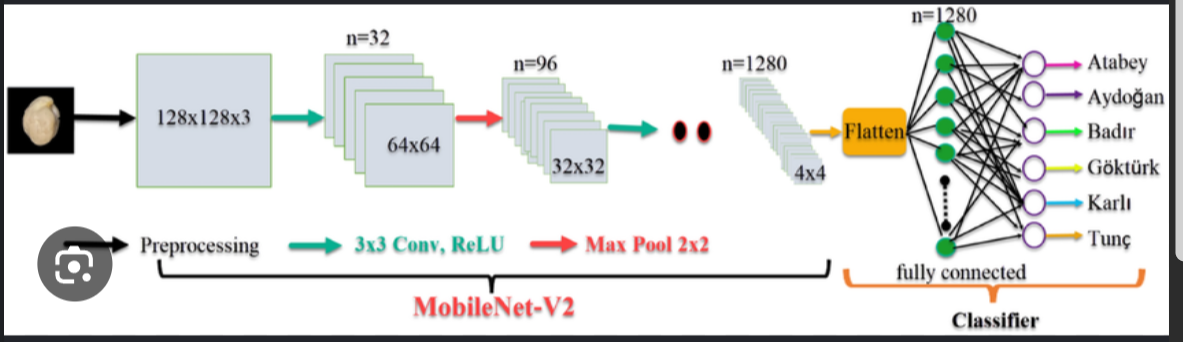

In [ ]:
from torchvision.models import mobilenet_v2, MobileNet_V2_Weights

In [ ]:
model = mobilenet_v2(
    weights=MobileNet_V2_Weights.DEFAULT
)

Downloading: "https://download.pytorch.org/models/mobilenet_v2-7ebf99e0.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-7ebf99e0.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 134MB/s]


In [ ]:
print(model)

MobileNetV2(
  (features): Sequential(
    (0): Conv2dNormActivation(
      (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
      (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      (2): ReLU6(inplace=True)
    )
    (1): InvertedResidual(
      (conv): Sequential(
        (0): Conv2dNormActivation(
          (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
          (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
          (2): ReLU6(inplace=True)
        )
        (1): Conv2d(32, 16, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (2): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
      )
    )
    (2): InvertedResidual(
      (conv): Sequential(
        (0): Conv2dNormActivation(
          (0): Conv2d(16, 96, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (1): BatchNorm2d(96, eps=

In [ ]:
model.classifier = nn.Sequential(

    nn.Dropout(0.5),

    nn.Linear(1280,3)

)

In [ ]:
for param in model.parameters():
    param.requires_grad = False

In [ ]:
for param in model.classifier.parameters():
    param.requires_grad = True

In [ ]:
model = model.to(device)

In [ ]:
criterion = nn.CrossEntropyLoss(
    weight=class_weights
)

In [ ]:
optimizer = torch.optim.Adam(
    model.classifier.parameters(),
    lr=0.0001
)

In [ ]:
from tqdm import tqdm

train_losses = []
train_accuracies = []

num_epochs = 15

for epoch in range(num_epochs):

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in tqdm(train_loader):

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        running_loss += loss.item()

        _, predicted = torch.max(outputs,1)

        total += labels.size(0)

        correct += (predicted==labels).sum().item()

    train_loss = running_loss/len(train_loader)
    train_accuracy = 100*correct/total

    train_losses.append(train_loss)
    train_accuracies.append(train_accuracy)

    print(
        f"Epoch [{epoch+1}/{num_epochs}] | "
        f"Loss: {train_loss:.4f} | "
        f"Accuracy: {train_accuracy:.2f}%"
    )

100%|██████████| 9/9 [00:06<00:00,  1.35it/s]


Epoch [1/15] | Loss: 1.0192 | Accuracy: 52.01%


100%|██████████| 9/9 [00:07<00:00,  1.22it/s]


Epoch [2/15] | Loss: 1.0111 | Accuracy: 55.31%


100%|██████████| 9/9 [00:06<00:00,  1.38it/s]


Epoch [3/15] | Loss: 1.0190 | Accuracy: 54.95%


... (20 outputs left out)

100%|██████████| 9/9 [00:07<00:00,  1.22it/s]


Epoch [14/15] | Loss: 0.9773 | Accuracy: 56.78%


100%|██████████| 9/9 [00:06<00:00,  1.38it/s]

Epoch [15/15] | Loss: 0.9608 | Accuracy: 58.42%


In [ ]:
model.eval()

val_running_loss = 0.0
val_correct = 0
val_total = 0

val_losses = []
val_accuracies = []

with torch.no_grad():

    for images, labels in val_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)

        loss = criterion(outputs, labels)

        val_running_loss += loss.item()

        _, predicted = torch.max(outputs,1)

        val_total += labels.size(0)

        val_correct += (predicted==labels).sum().item()

val_loss = val_running_loss/len(val_loader)

val_accuracy = 100*val_correct/val_total

val_losses.append(val_loss)
val_accuracies.append(val_accuracy)

print(f"Validation Loss: {val_loss:.4f}")
print(f"Validation Accuracy: {val_accuracy:.2f}%")

Validation Loss: 1.0040
Validation Accuracy: 56.41%


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

model.eval()

test_running_loss = 0.0
test_correct = 0
test_total = 0

all_labels = []
all_predictions = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)

        loss = criterion(outputs, labels)

        test_running_loss += loss.item()

        _, predicted = torch.max(outputs,1)

        test_total += labels.size(0)

        test_correct += (predicted==labels).sum().item()

        all_labels.extend(labels.cpu().numpy())

        all_predictions.extend(predicted.cpu().numpy())

test_loss = test_running_loss/len(test_loader)

test_accuracy = 100*test_correct/test_total

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.2f}%")

Test Loss: 0.9674
Test Accuracy: 70.09%


In [ ]:
precision = precision_score(
    all_labels,
    all_predictions,
    average="weighted"
)

recall = recall_score(
    all_labels,
    all_predictions,
    average="weighted"
)

f1 = f1_score(
    all_labels,
    all_predictions,
    average="weighted"
)

print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1 Score  : {f1:.4f}")

Precision : 0.7006
Recall    : 0.7009
F1 Score  : 0.6973


In [ ]:
print(classification_report(
    all_labels,
    all_predictions,
    target_names=[
        "Benign",
        "Malignant",
        "Normal"
    ]
))

              precision    recall  f1-score   support

      Benign       0.71      0.81      0.75        57
   Malignant       0.74      0.62      0.68        40
      Normal       0.61      0.55      0.58        20

    accuracy                           0.70       117
   macro avg       0.68      0.66      0.67       117
weighted avg       0.70      0.70      0.70       117



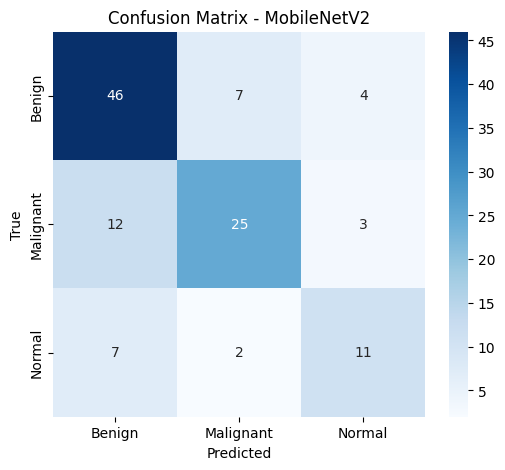

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(
    all_labels,
    all_predictions
)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[
        "Benign",
        "Malignant",
        "Normal"
    ],
    yticklabels=[
        "Benign",
        "Malignant",
        "Normal"
    ]
)

plt.xlabel("Predicted")

plt.ylabel("True")

plt.title("Confusion Matrix - MobileNetV2")

plt.show()

XAI FOR MOBILENET

GRADCAM

In [ ]:
import torch
import numpy as np
import matplotlib.pyplot as plt

from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from pytorch_grad_cam.utils.image import show_cam_on_image

In [ ]:
model.eval()
for param in model.parameters():
    param.requires_grad = True

In [ ]:
target_layers = [
    model.features[-1][0]
]

In [ ]:
image, label = test_dataset[0]

input_tensor = image.unsqueeze(0).to(device)

print("True Label:", label)

True Label: 0


In [ ]:
cam = GradCAM(
    model=model,
    target_layers=target_layers
)

targets = [
    ClassifierOutputTarget(label)
]

grayscale_cam = cam(
    input_tensor=input_tensor,
    targets=targets
)

grayscale_cam = grayscale_cam[0]

In [ ]:
img = image.permute(1,2,0).cpu().numpy()


mean = np.array([0.485,0.456,0.406])
std = np.array([0.229,0.224,0.225])


img = std * img + mean

img = np.clip(img,0,1)

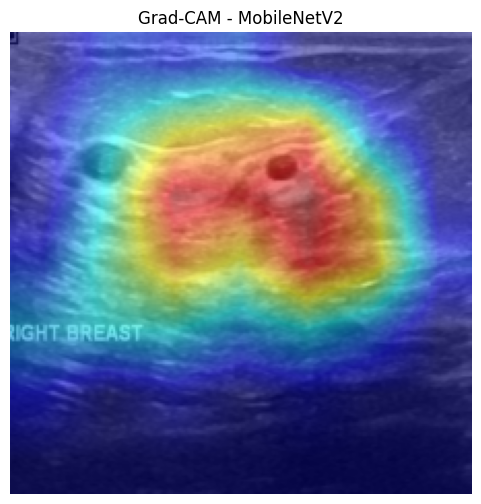

In [ ]:
visualization = show_cam_on_image(
    img,
    grayscale_cam,
    use_rgb=True
)


plt.figure(figsize=(6,6))

plt.imshow(visualization)

plt.axis("off")

plt.title("Grad-CAM - MobileNetV2")

plt.show()

In [ ]:
plt.savefig(
    "mobilenetv2_gradcam.png",
    bbox_inches="tight",
    dpi=300
)

plt.show()

<Figure size 640x480 with 0 Axes>

Predicted Class: 0
SHAP shape: (224, 224, 3)


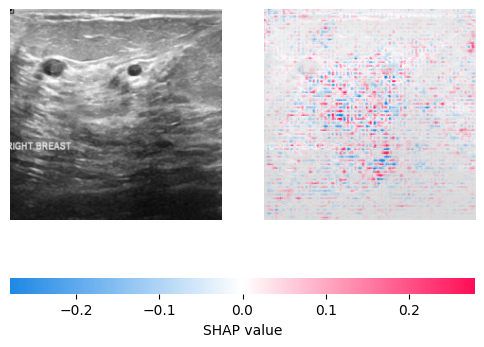

In [ ]:

import shap
import torch
import numpy as np
import matplotlib.pyplot as plt


model.eval()

for param in model.parameters():
    param.requires_grad = True


image, label = test_dataset[0]

input_tensor = image.unsqueeze(0).to(device)


background = []

for i in range(10):
    img, _ = train_dataset[i]
    background.append(img)

background = torch.stack(background).to(device)


explainer = shap.GradientExplainer(
    model,
    background
)


shap_values = explainer.shap_values(
    input_tensor
)


with torch.no_grad():

    output = model(input_tensor)

    predicted_class = torch.argmax(
        output,
        dim=1
    ).item()


print("Predicted Class:", predicted_class)


shap_values = np.array(shap_values)


if shap_values.ndim == 5:
    shap_values = shap_values[0]


shap_class = shap_values[predicted_class]


print("SHAP shape:", shap_class.shape)


img = image.permute(1,2,0).cpu().numpy()


mean = np.array([0.485,0.456,0.406])
std = np.array([0.229,0.224,0.225])


img = std * img + mean

img = np.clip(img,0,1)


shap_heatmap = np.abs(shap_class).mean(axis=2)


shap_heatmap = (
    shap_heatmap - shap_heatmap.min()
) / (
    shap_heatmap.max() - shap_heatmap.min()
)




import shap

shap_values_plot = shap_class[np.newaxis,:,:,:]

img_plot = img[np.newaxis,:,:,:]


shap.image_plot(
    [shap_values_plot],
    img_plot
)

  0%|          | 0/100 [00:00<?, ?it/s]

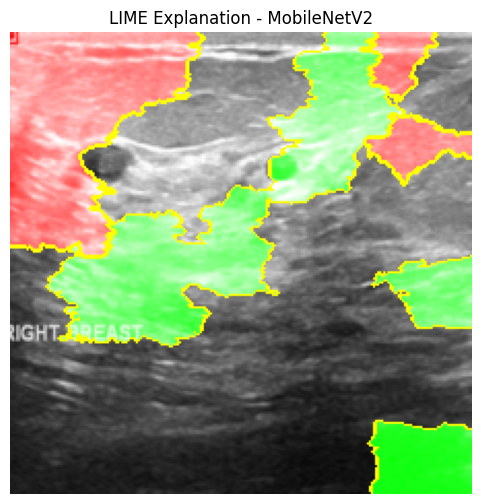

In [ ]:

import torch
import numpy as np
import matplotlib.pyplot as plt

from lime import lime_image
from skimage.segmentation import mark_boundaries


model.eval()


image, label = test_dataset[0]

img = image.permute(1,2,0).cpu().numpy()

mean = np.array([0.485,0.456,0.406])
std = np.array([0.229,0.224,0.225])

img = std * img + mean

img = np.clip(img,0,1)


def predict(images):

    images = torch.tensor(images).permute(0,3,1,2).float()

    images = images.to(device)

    with torch.no_grad():

        outputs = model(images)

        probs = torch.softmax(outputs,dim=1)

    return probs.cpu().numpy()



explainer = lime_image.LimeImageExplainer()


explanation = explainer.explain_instance(
    img,
    predict,
    top_labels=3,
    hide_color=0,
    num_samples=100
)


predicted_class = explanation.top_labels[0]


temp, mask = explanation.get_image_and_mask(
    predicted_class,
    positive_only=False,
    num_features=10,
    hide_rest=False
)


plt.figure(figsize=(6,6))

plt.imshow(
    mark_boundaries(
        temp,
        mask
    )
)

plt.axis("off")

plt.title("LIME Explanation - MobileNetV2")

plt.show()

VGG16
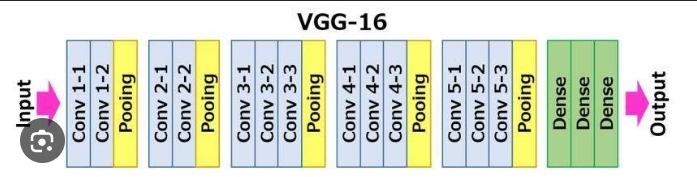

In [ ]:
from torchvision.models import vgg16, VGG16_Weights
import torch
import torch.nn as nn

model = vgg16(weights=VGG16_Weights.DEFAULT)

model.classifier = nn.Sequential(
    nn.Linear(25088, 4096),
    nn.ReLU(),
    nn.Dropout(0.5),

    nn.Linear(4096, 1024),
    nn.ReLU(),
    nn.Dropout(0.5),

    nn.Linear(1024, 3)
)

for param in model.features.parameters():
    param.requires_grad = False

for param in model.classifier.parameters():
    param.requires_grad = True

model = model.to(device)

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    model.classifier.parameters(),
    lr=0.001
)

Downloading: "https://download.pytorch.org/models/vgg16-397923af.pth" to /root/.cache/torch/hub/checkpoints/vgg16-397923af.pth


100%|██████████| 528M/528M [00:04<00:00, 120MB/s]


In [ ]:
from tqdm import tqdm

train_losses = []
train_accuracies = []

num_epochs = 15

for epoch in range(num_epochs):

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in tqdm(train_loader):

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        running_loss += loss.item()

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)

        correct += (predicted == labels).sum().item()

    train_loss = running_loss / len(train_loader)

    train_accuracy = 100 * correct / total

    train_losses.append(train_loss)
    train_accuracies.append(train_accuracy)

    print(
        f"Epoch [{epoch+1}/{num_epochs}] | "
        f"Loss: {train_loss:.4f} | "
        f"Accuracy: {train_accuracy:.2f}%"
    )

100%|██████████| 9/9 [00:09<00:00,  1.09s/it]


Epoch [1/15] | Loss: 3.1549 | Accuracy: 46.52%


100%|██████████| 9/9 [00:09<00:00,  1.06s/it]


Epoch [2/15] | Loss: 0.9074 | Accuracy: 57.69%


100%|██████████| 9/9 [00:09<00:00,  1.05s/it]


Epoch [3/15] | Loss: 0.8230 | Accuracy: 59.52%


... (20 outputs left out)

100%|██████████| 9/9 [00:09<00:00,  1.08s/it]


Epoch [14/15] | Loss: 0.3709 | Accuracy: 85.35%


100%|██████████| 9/9 [00:09<00:00,  1.07s/it]

Epoch [15/15] | Loss: 0.3118 | Accuracy: 87.18%


In [ ]:
torch.save(
    model.state_dict(),
    "vgg16_final.pth"
)

print("VGG16 Saved Successfully!")

VGG16 Saved Successfully!


In [ ]:
model.eval()

val_running_loss = 0.0
val_correct = 0
val_total = 0

val_losses = []
val_accuracies = []

with torch.no_grad():

    for images, labels in val_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)

        loss = criterion(outputs, labels)

        val_running_loss += loss.item()

        _, predicted = torch.max(outputs, 1)

        val_total += labels.size(0)

        val_correct += (predicted == labels).sum().item()

val_loss = val_running_loss / len(val_loader)

val_accuracy = 100 * val_correct / val_total

val_losses.append(val_loss)
val_accuracies.append(val_accuracy)

print(f"Validation Loss: {val_loss:.4f}")
print(f"Validation Accuracy: {val_accuracy:.2f}%")

Validation Loss: 0.5658
Validation Accuracy: 80.34%


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

model.eval()

test_running_loss = 0.0
test_correct = 0
test_total = 0

all_labels = []
all_predictions = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)

        loss = criterion(outputs, labels)

        test_running_loss += loss.item()

        _, predicted = torch.max(outputs, 1)

        test_total += labels.size(0)

        test_correct += (predicted == labels).sum().item()

        all_labels.extend(labels.cpu().numpy())

        all_predictions.extend(predicted.cpu().numpy())

test_loss = test_running_loss / len(test_loader)

test_accuracy = 100 * test_correct / test_total

print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.2f}%")

Test Loss: 0.5104
Test Accuracy: 86.32%


In [ ]:
precision = precision_score(
    all_labels,
    all_predictions,
    average="weighted"
)

recall = recall_score(
    all_labels,
    all_predictions,
    average="weighted"
)

f1 = f1_score(
    all_labels,
    all_predictions,
    average="weighted"
)

print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1 Score  : {f1:.4f}")

Precision : 0.8700
Recall    : 0.8632
F1 Score  : 0.8615


In [ ]:
print(classification_report(
    all_labels,
    all_predictions,
    target_names=[
        "Benign",
        "Malignant",
        "Normal"
    ]
))

              precision    recall  f1-score   support

      Benign       0.84      0.95      0.89        57
   Malignant       0.94      0.75      0.83        40
      Normal       0.81      0.85      0.83        20

    accuracy                           0.86       117
   macro avg       0.86      0.85      0.85       117
weighted avg       0.87      0.86      0.86       117



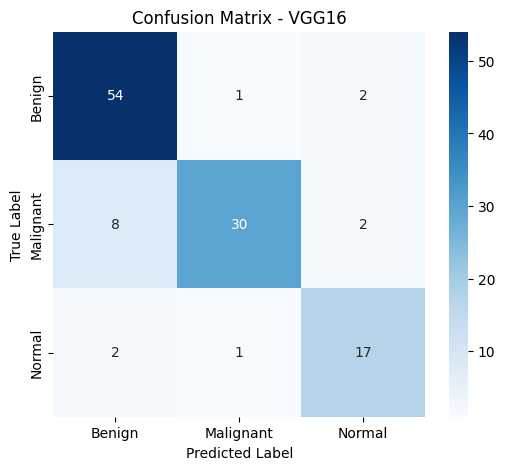

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(
    all_labels,
    all_predictions
)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[
        "Benign",
        "Malignant",
        "Normal"
    ],
    yticklabels=[
        "Benign",
        "Malignant",
        "Normal"
    ]
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix - VGG16")

plt.show()

Predicted Class: 0


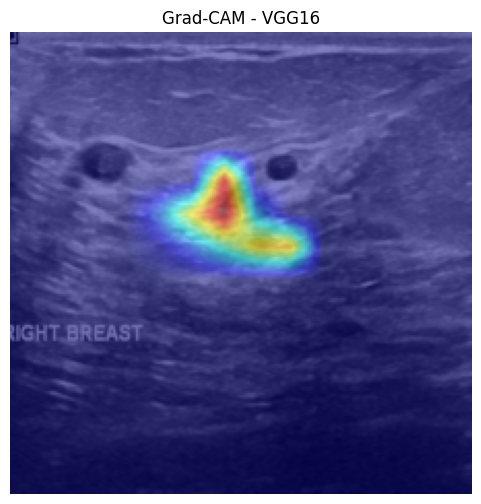

In [ ]:
import torch
import numpy as np
import matplotlib.pyplot as plt

from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
from pytorch_grad_cam.utils.image import show_cam_on_image


model.eval()

for param in model.parameters():
    param.requires_grad = True


image, label = test_dataset[0]

input_tensor = image.unsqueeze(0).to(device)


output = model(input_tensor)

predicted_class = torch.argmax(
    output,
    dim=1
).item()

print("Predicted Class:", predicted_class)



target_layers = [
    model.features[28]
]


cam = GradCAM(
    model=model,
    target_layers=target_layers
)


targets = [
    ClassifierOutputTarget(predicted_class)
]


grayscale_cam = cam(
    input_tensor=input_tensor,
    targets=targets
)


grayscale_cam = grayscale_cam[0]



img = image.permute(1,2,0).cpu().numpy()


mean = np.array([0.485,0.456,0.406])
std = np.array([0.229,0.224,0.225])


img = std * img + mean

img = np.clip(img,0,1)



visualization = show_cam_on_image(
    img,
    grayscale_cam,
    use_rgb=True
)


plt.figure(figsize=(6,6))

plt.imshow(visualization)

plt.axis("off")

plt.title("Grad-CAM - VGG16")

plt.show()

Predicted Class: 0
SHAP shape: (224, 224, 3)


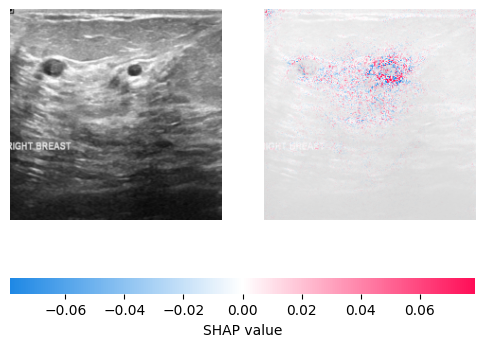

In [ ]:
!pip install shap

import shap
import torch
import numpy as np
import matplotlib.pyplot as plt


model.eval()

for param in model.parameters():
    param.requires_grad = True



image, label = test_dataset[0]

input_tensor = image.unsqueeze(0).to(device)



background = []

for i in range(10):
    img, _ = train_dataset[i]
    background.append(img)

background = torch.stack(background).to(device)



explainer = shap.GradientExplainer(
    model,
    background
)


shap_values = explainer.shap_values(
    input_tensor
)



with torch.no_grad():

    output = model(input_tensor)

    predicted_class = torch.argmax(
        output,
        dim=1
    ).item()


print("Predicted Class:", predicted_class)



shap_values = np.array(shap_values)


if shap_values.ndim == 5:
    shap_values = shap_values[0]


shap_class = shap_values[predicted_class]


print("SHAP shape:", shap_class.shape)



img = image.permute(1,2,0).cpu().numpy()


mean = np.array([0.485,0.456,0.406])
std = np.array([0.229,0.224,0.225])


img = std * img + mean

img = np.clip(img,0,1)



shap.image_plot(
    [shap_class[np.newaxis,:,:,:]],
    img[np.newaxis,:,:,:]
)

  0%|          | 0/100 [00:00<?, ?it/s]

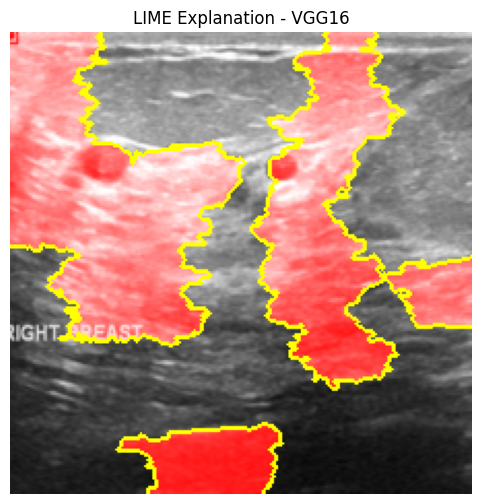

In [ ]:

import torch
import numpy as np
import matplotlib.pyplot as plt

from lime import lime_image
from skimage.segmentation import mark_boundaries


model.eval()


image, label = test_dataset[0]


img = image.permute(1,2,0).cpu().numpy()


mean = np.array([0.485,0.456,0.406])
std = np.array([0.229,0.224,0.225])


img = std * img + mean

img = np.clip(img,0,1)



def predict(images):

    images = torch.tensor(images).permute(0,3,1,2).float()

    images = images.to(device)


    with torch.no_grad():

        outputs = model(images)

        probs = torch.softmax(
            outputs,
            dim=1
        )

    return probs.cpu().numpy()



explainer = lime_image.LimeImageExplainer()


explanation = explainer.explain_instance(
    img,
    predict,
    top_labels=3,
    hide_color=0,
    num_samples=100
)



predicted_class = explanation.top_labels[0]


temp, mask = explanation.get_image_and_mask(
    predicted_class,
    positive_only=False,
    num_features=10,
    hide_rest=False
)



plt.figure(figsize=(6,6))

plt.imshow(
    mark_boundaries(
        temp,
        mask
    )
)

plt.axis("off")

plt.title("LIME Explanation - VGG16")

plt.show()

custom cnn

In [ ]:
class CustomCNN(nn.Module):

    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(

            nn.Conv2d(3,64,3,padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(64,128,3,padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(128,256,3,padding=1),
            nn.BatchNorm2d(256),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(256,512,3,padding=1),
            nn.BatchNorm2d(512),
            nn.ReLU(),

            nn.AdaptiveAvgPool2d(1)
        )


        self.classifier = nn.Sequential(

            nn.Flatten(),

            nn.Linear(512,256),
            nn.ReLU(),
            nn.Dropout(0.6),

            nn.Linear(256,3)
        )


    def forward(self,x):

        x=self.features(x)
        x=self.classifier(x)

        return x

In [ ]:
model = CustomCNN()

model = model.to(device)

In [ ]:
criterion = nn.CrossEntropyLoss(

)


optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.0001,
)

In [ ]:
from tqdm import tqdm


num_epochs = 20


train_losses=[]
train_accuracies=[]


for epoch in range(num_epochs):

    model.train()

    running_loss=0
    correct=0
    total=0


    for images,labels in tqdm(train_loader):

        images=images.to(device)
        labels=labels.to(device)


        optimizer.zero_grad()


        outputs=model(images)


        loss=criterion(
            outputs,
            labels
        )


        loss.backward()


        optimizer.step()


        running_loss += loss.item()


        _,predicted=torch.max(outputs,1)


        total += labels.size(0)

        correct += (predicted==labels).sum().item()



    train_loss = running_loss/len(train_loader)

    train_accuracy = 100*correct/total


    train_losses.append(train_loss)

    train_accuracies.append(train_accuracy)



    print(
        f"Epoch [{epoch+1}/{num_epochs}] | "
        f"Loss: {train_loss:.4f} | "
        f"Accuracy: {train_accuracy:.2f}%"
    )

100%|██████████| 9/9 [00:09<00:00,  1.00s/it]


Epoch [1/20] | Loss: 1.0275 | Accuracy: 48.53%


100%|██████████| 9/9 [00:08<00:00,  1.00it/s]


Epoch [2/20] | Loss: 0.9351 | Accuracy: 59.52%


100%|██████████| 9/9 [00:08<00:00,  1.07it/s]


Epoch [3/20] | Loss: 0.8935 | Accuracy: 60.07%


... (30 outputs left out)

100%|██████████| 9/9 [00:09<00:00,  1.01s/it]


Epoch [19/20] | Loss: 0.7510 | Accuracy: 67.58%


100%|██████████| 9/9 [00:09<00:00,  1.02s/it]

Epoch [20/20] | Loss: 0.7452 | Accuracy: 69.23%


In [ ]:
torch.save(
    model.state_dict(),
    "customcnn_final.pth"
)

In [ ]:
model.eval()


val_running_loss=0
val_correct=0
val_total=0


with torch.no_grad():

    for images,labels in val_loader:

        images=images.to(device)
        labels=labels.to(device)


        outputs=model(images)


        loss=criterion(
            outputs,
            labels
        )


        val_running_loss += loss.item()


        _,predicted=torch.max(outputs,1)


        val_total += labels.size(0)

        val_correct += (predicted==labels).sum().item()



val_loss = val_running_loss/len(val_loader)

val_accuracy = 100*val_correct/val_total


print(
    f"Validation Loss: {val_loss:.4f}"
)

print(
    f"Validation Accuracy: {val_accuracy:.2f}%"
)

Validation Loss: 0.8931
Validation Accuracy: 60.68%


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)


model.eval()


all_labels=[]
all_predictions=[]


with torch.no_grad():

    for images,labels in test_loader:

        images=images.to(device)
        labels=labels.to(device)


        outputs=model(images)


        _,predicted=torch.max(outputs,1)


        all_labels.extend(
            labels.cpu().numpy()
        )


        all_predictions.extend(
            predicted.cpu().numpy()
        )



print(
    "Accuracy:",
    accuracy_score(
        all_labels,
        all_predictions
    )
)


print(
    "Precision:",
    precision_score(
        all_labels,
        all_predictions,
        average="weighted"
    )
)


print(
    "Recall:",
    recall_score(
        all_labels,
        all_predictions,
        average="weighted"
    )
)


print(
    "F1:",
    f1_score(
        all_labels,
        all_predictions,
        average="weighted"
    )
)



print(
    classification_report(
        all_labels,
        all_predictions,
        target_names=[
            "Benign",
            "Malignant",
            "Normal"
        ]
    )
)

Accuracy: 0.6837606837606838
Precision: 0.7052822052822053
Recall: 0.6837606837606838
F1: 0.6610813340114573
              precision    recall  f1-score   support

      Benign       0.66      0.86      0.75        57
   Malignant       0.70      0.65      0.68        40
      Normal       0.83      0.25      0.38        20

    accuracy                           0.68       117
   macro avg       0.73      0.59      0.60       117
weighted avg       0.71      0.68      0.66       117



Comparision between Models

In [ ]:
import pandas as pd

comparison = pd.DataFrame({

    "Model": [
        "ResNet50",
        "MobileNetV2",
        "VGG16",
        "Custom CNN"
    ],

    "Test Accuracy (%)": [
        73.50,
        70.09,
        86.32,
        68.37
    ],

    "Precision": [
        0.74,
        0.70,
        0.87,      # replace with exact value from your VGG results
        0.71
    ],

    "Recall": [
        0.73,
        0.70,
        0.86,      # replace with exact value
        0.68
    ],

    "F1-Score": [
        0.73,
        0.70,
        0.86,      # replace with exact value
        0.66
    ],

    "Transfer Learning": [
        "Yes",
        "Yes",
        "Yes",
        "No"
    ],

    "XAI Techniques": [
        "Grad-CAM, SHAP, LIME",
        "Grad-CAM, SHAP, LIME",
        "Grad-CAM, SHAP, LIME",
        "Not Applied"
    ]
})

comparison = comparison.sort_values(
    by="Test Accuracy (%)",
    ascending=False
).reset_index(drop=True)

print(comparison)

         Model  Test Accuracy (%)  Precision  Recall  F1-Score  \
0        VGG16              86.32       0.87    0.86      0.86   
1     ResNet50              73.50       0.74    0.73      0.73   
2  MobileNetV2              70.09       0.70    0.70      0.70   
3   Custom CNN              68.37       0.71    0.68      0.66   

  Transfer Learning        XAI Techniques  
0               Yes  Grad-CAM, SHAP, LIME  
1               Yes  Grad-CAM, SHAP, LIME  
2               Yes  Grad-CAM, SHAP, LIME  
3                No           Not Applied  


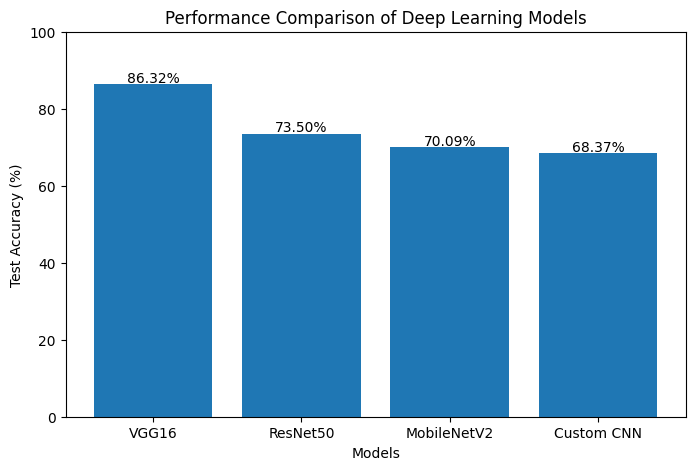

In [ ]:
import matplotlib.pyplot as plt

models = comparison["Model"]
accuracy = comparison["Test Accuracy (%)"]

plt.figure(figsize=(8,5))

plt.bar(models, accuracy)

plt.ylabel("Test Accuracy (%)")
plt.xlabel("Models")
plt.title("Performance Comparison of Deep Learning Models")

for i, value in enumerate(accuracy):
    plt.text(i, value + 0.5, f"{value:.2f}%", ha="center")

plt.ylim(0,100)

plt.show()